<a href="https://colab.research.google.com/github/muhammad-faizan087/Deep-Learning-Projects/blob/main/ANN/tuning_hyperparameters_of_ann_using_optuna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What are we doing?

- earlier we trained an ANN using the hyperparameter values from our own intution, they can be not the best ones. To find best values for all the hyperparameters in an ANN - we'll do some experimentation and for that we'll use optuna library

- for details of how it's done, refer to the notes

In [ ]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using Device: {device}")

Using Device: cuda


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zalando-research/fashionmnist")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fashionmnist' dataset.
Path to dataset files: /kaggle/input/fashionmnist


In [ ]:
df = pd.read_csv(f'{path}/fashion-mnist_train.csv')
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
X = df.drop('label', axis=1)
y = df['label']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

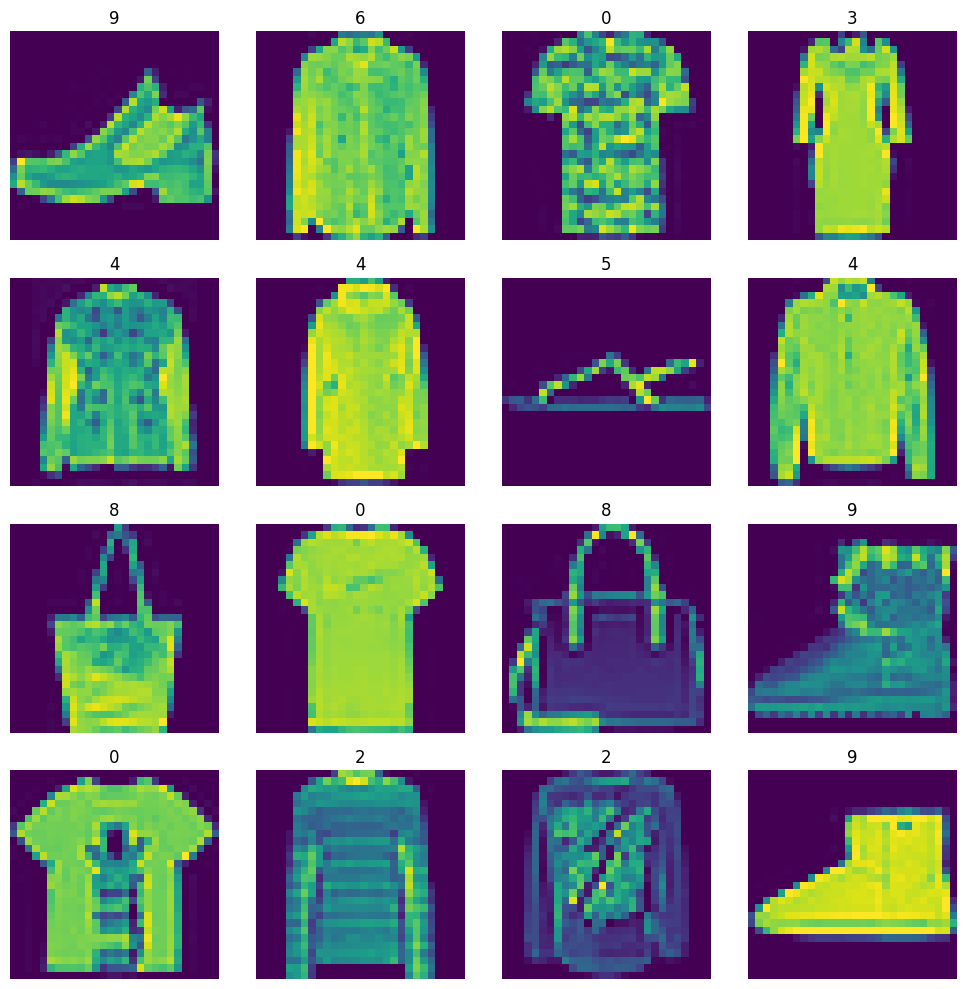

In [ ]:
plt.figure(figsize=(10, 10))

for i in range(1, 17):
    plt.subplot(4, 4, i)
    plt.imshow(X.iloc[i].values.reshape(28, 28))
    plt.title(y.iloc[i])
    plt.axis('off')

plt.tight_layout()

In [ ]:
X_train = X_train/255.0
X_test = X_test/255.0   # above we can see that pixels values are from 0 to 255, for NN it's good to keep values b/w 0 and 1 so that's why we divided by 255

In [ ]:
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.long)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.long)

In [ ]:
class CustomDataset(Dataset):
  def __init__(self, features, labels):
       self.features = features
       self.labels = labels

  def __len__(self):
       return len(self.features)

  def __getitem__(self, idx):
       return self.features[idx], self.labels[idx]

In [ ]:
train_dataset = CustomDataset(X_train_tensor, y_train_tensor)
test_dataset = CustomDataset(X_test_tensor, y_test_tensor)

In [ ]:
class MyOptimizedNN(nn.Module):

  def __init__(self, input_dim, output_dim, num_hidden_layers, neurons_per_layer, dropout_rate):

    super().__init__()

    layers = []

    for i in range(num_hidden_layers):
      layers.append(nn.Linear(input_dim, neurons_per_layer))
      layers.append(nn.BatchNorm1d(neurons_per_layer))
      layers.append(nn.ReLU())
      layers.append(nn.Dropout(p = dropout_rate))
      input_dim = neurons_per_layer
    layers.append(nn.Linear(input_dim, output_dim))

    self.network = nn.Sequential(*layers)

  def forward(self, x):
    return self.network(x)

In [ ]:
# objective func

def Objective(trial):

  # next hyperparameter values from the search space
  num_hidden_layers = trial.suggest_int('num_hidden_layers', 1, 5)
  # neurons_per_layer = trial.suggest_categorical('neurons_per_layer', [32, 64, 128, 256])
  neurons_per_layer = trial.suggest_int('neurons_per_layer', 8, 128, step=8)
  epochs = trial.suggest_int('epochs', 10, 50)
  learning_rate = trial.suggest_float('learning_rate', 1e-5, 1e-1, log=True)
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5, step=0.1)
  batch_size = trial.suggest_categorical('batch_size', [16, 32, 64, 128])
  optimizer_name = trial.suggest_categorical("optimizer", ['Adam', 'SGD', 'RMSprop'])
  weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)

  train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
  test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

  # model initialization
  input_dim = X_train_tensor.shape[1]
  output_dim = 10
  model = MyOptimizedNN(input_dim, output_dim, num_hidden_layers, neurons_per_layer, dropout_rate)
  model.to(device)

  # optimizer selection
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=0.1, weight_decay=1e-4)

  if optimizer_name == 'Adam':
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
  elif optimizer_name == 'SGD':
    optimizer = optim.SGD(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
  else:
    optimizer = optim.RMSprop(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

  # training loop
  for epoch in range(epochs):

    for batch_features, batch_labels in train_dataloader:

        batch_features, batch_labels = batch_features.to(device), batch_labels.to(device) # moving training data to gpu

        outputs = model(batch_features)

        loss = criterion(outputs, batch_labels)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

  # evaluation
  model.eval()
  # evaluation on test data
  total = 0
  correct = 0

  with torch.no_grad():

    for b_features, b_labels in test_dataloader:
      b_features, b_labels = b_features.to(device), b_labels.to(device) # moving test data to gpu
      outputs = model(b_features) # for each i/p image(sample), output would be a tensor of size 10 having probabilties for image to belong to each of the 10 classes

      loss = criterion(outputs, b_labels)

      _, predicted = torch.max(outputs, 1) # the class with max probability would be consider, to get the label of class (the index in the tensor is the label). max() returns max value and index where that max value is

      total += b_labels.shape[0]
      correct += (predicted == b_labels).sum().item()

    accuracy = (correct/total)

  return accuracy




In [ ]:
!pip install optuna

In [ ]:
import optuna



In [ ]:
study = optuna.create_study(direction='maximize') # since we are doing it on accuracy so dir=maximize, if we'll have loss then dir will be minimize

[I 2026-09-15 11:50:22,656] A new study created in memory with name: no-name-c5ada06a-8cc8-41b5-a12a-ad25637b35b4


In [ ]:
study.optimize(Objective, n_trials=10)

[I 2026-09-15 11:52:30,878] Trial 0 finished with value: 0.8313333333333334 and parameters: {'num_hidden_layers': 2, 'neurons_per_layer': 16, 'epochs': 26, 'learning_rate': 0.04153204208178213, 'dropout_rate': 0.30000000000000004, 'batch_size': 16, 'optimizer': 'SGD', 'weight_decay': 0.00020291718552044045}. Best is trial 0 with value: 0.8313333333333334.
[I 2026-09-15 11:53:39,474] Trial 1 finished with value: 0.8686666666666667 and parameters: {'num_hidden_layers': 1, 'neurons_per_layer': 128, 'epochs': 17, 'learning_rate': 0.0016816245534459918, 'dropout_rate': 0.5, 'batch_size': 32, 'optimizer': 'SGD', 'weight_decay': 1.1891542890197959e-05}. Best is trial 1 with value: 0.8686666666666667.
[I 2026-09-15 11:56:13,874] Trial 2 finished with value: 0.622 and parameters: {'num_hidden_layers': 2, 'neurons_per_layer': 48, 'epochs': 30, 'learning_rate': 0.04252450962180308, 'dropout_rate': 0.1, 'batch_size': 16, 'optimizer': 'RMSprop', 'weight_decay': 0.0007346009932829808}. Best is trial

In [ ]:
study.best_value

0.8861666666666667

In [ ]:
study.best_params

{'num_hidden_layers': 2,
 'neurons_per_layer': 64,
 'epochs': 47,
 'learning_rate': 0.06618976500192425,
 'dropout_rate': 0.2,
 'batch_size': 128,
 'optimizer': 'SGD',
 'weight_decay': 0.00014551733603985513}